### DBSCAN

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_iris
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import DBSCAN

In [2]:
data = load_iris()

X = pd.DataFrame(
    data.data,
    columns=data.feature_names
)

print(X.head())

   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)
0                5.1               3.5                1.4               0.2
1                4.9               3.0                1.4               0.2
2                4.7               3.2                1.3               0.2
3                4.6               3.1                1.5               0.2
4                5.0               3.6                1.4               0.2


In [3]:
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

In [22]:
model = DBSCAN(
    eps=0.8,
    min_samples=5
)

In [23]:
clusters = model.fit_predict(X_scaled)

In [24]:
print(clusters)

[ 0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0
  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0 -1  0  0  0  0  0  0
  0  0  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1
  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1
  1  1  1  1  1  1  1  1  1  1  1  1  1 -1  1  1  1  1  1  1  1 -1  1  1
  1  1  1  1  1  1  1  1  1  1  1 -1  1  1  1  1  1  1  1  1  1  1  1  1
  1  1  1  1  1  1]


In [25]:
print(pd.Series(clusters).value_counts())

 1    97
 0    49
-1     4
Name: count, dtype: int64


In [26]:
print(clusters[:20])

[0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]


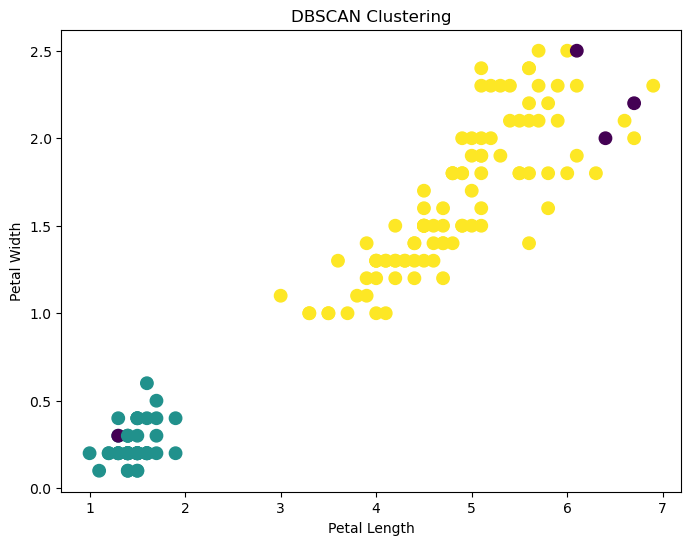

In [27]:
plt.figure(figsize=(8,6))

plt.scatter(
    X["petal length (cm)"],
    X["petal width (cm)"],
    c=clusters,
    cmap="viridis",
    s=80
)

plt.xlabel("Petal Length")
plt.ylabel("Petal Width")
plt.title("DBSCAN Clustering")

plt.show()

In [28]:
from sklearn.metrics import silhouette_score

score = silhouette_score(X_scaled, clusters)

print(score)

0.5216965052515835
